# Real flat tables ranked among synthetic tables of the same schema

**Contents**
1. Motivation
2. Load the real tables
3. Results: Coverage
4. Results: Realism
5. Results: Sizes and column types
6. Conclusion

References


## 1. Motivation

A simulator of tabular data is only as useful as its tables are realistic.<br>
`tabdgp` draws a table from a structural causal model (SCM), whose sizes, column types, marginal shapes and dependence follow default distributions.<br>
So far, no test has compared these defaults with real tables.

### 1.1 Setup
This experiment compares synthetic tables with the real flat tables (tables without a grouping structure) of `mixedbench` 1.0.15, one real table at a time.<br>
For each real table, a simulator draws 39 synthetic tables with the same number of rows and the same column types.<br>
A calibrated simulator makes the real table one of 40 exchangeable tables, so it should not stand out among them (Talts et al., 2020).<br>
We compare three simulators:
- **default:** `tabdgp` at its default settings.
- **independent:** `tabdgp` with covariates that are drawn independently of each other. This is a negative control, on which the comparison has to fail.
- **TabICL:** the prior on which TabICLv2 was pretrained (Qu et al., 2026), as a reference. It takes the number of rows and columns but no column types.

### 1.2 Measures
We summarize each table by up to 83 statistics:
- **Marginal shape:** per column type, e.g. the skewness of a continuous column, the share of its rows at its larger end beyond the share of a typical value, or the largest level share of a categorical one, as the median and the maximum over the table's columns of that type.
- **Associations:** each column's largest association with another column (rank correlation, correlation ratio or Cramér's V, by the types of the pair), the condition index of the design matrix, and the leverage, Mardia's (1970) multivariate kurtosis of the continuous columns' normal scores, which shows a few rows that lie far from the rest jointly.
- **Response:** its marginal shape and its largest association with a covariate.

A table has no value for a statistic that it cannot show (e.g. a level share without a categorical column).<br>
On these statistics, we report:
- **Outside share:** the share of real tables below or above all of their 39 synthetic tables. A calibrated simulator leaves 5% outside. A statistic fails if more tables lie outside than a binomial count allows, at a level of 0.01 over all statistics.
- **Mean rank:** the real table's mean rank among its synthetic tables, from 0 to 1. It is 0.5 if the synthetic tables are centered on the real ones.
- **Precision:** the share of synthetic tables that lie at least as close to their 5 nearest real tables as their own real table does (cf. Naeem et al., 2020). The distance ranks each statistic among the real tables of other sources ([distance.ipynb](distance.ipynb)). A calibrated simulator scores 0.5, and we require 0.25.
- **Two-sample test:** the cross-validated accuracy of a random forest that tells real from synthetic tables (Lopez-Paz & Oquab, 2017), where 0.5 is chance.

## 2. Load the real tables

- **Preparation:** we drop columns that are mostly missing, row labels and constant columns, then rows with a missing value. A column of numbers is read as continuous.
- **Halves:** the sources are split at random into a fitting half, on which the defaults may later be tuned, and a certifying half. We report the certifying half.
- **Sizes:** we report the tables whose sizes the defaults draw (20 to 15,000 rows, up to 19 design columns and at least two rows per design column).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import HTML, display

# the simulators by their arm in flat-report.csv
SIMULATORS = {'default': 'default', 'independent': 'independent', 'tabicl': 'TabICL'}
PART = 'certifying'  # the half of the sources that no later fit of the defaults reads
STRATUM = 'inside'  # the tables whose sizes the defaults draw
FEWEST = 20  # a statistic ranked on fewer real tables is not shown
TYPES = ['continuous', 'count', 'binary', 'categorical', 'ordered']
# the statistics a synthetic table shares with its real table by construction
STATED = ['rows', 'design_columns', 'columns', 'levels_median', 'levels_max']
STATED += [f'{type}_share' for type in TYPES]
WORDS = {
    'skewness': 'skewness',
    'excess_kurtosis': 'excess kurtosis',
    'outlier_share': 'outlier share',
    'zero_share': 'zero share',
    'distinct_share': 'distinct share',
    'mode_share': 'mode share',
    'bound_excess': 'excess at a bound',
    'dispersion': 'dispersion',
    'largest_level_share': 'largest level share',
    'smallest_level_share': 'smallest level share',
    'relation': 'largest association',
}

real = pd.read_csv('flat-real.csv')
left_out = pd.read_csv('flat-left-out.csv')
report = pd.read_csv('flat-report.csv')


def labelStatistic(axis: str) -> str:
    # a statistic in words: its block, the column type and the aggregate over the columns
    if axis == 'condition_index':
        return 'associations: condition index'
    if axis == 'leverage':
        return 'associations: leverage'
    if axis == 'y_relation':
        return 'response: largest association'
    type, statistic = axis.removeprefix('y_').split('_', 1)
    if axis.startswith('y_'):
        return f'response ({type}): {WORDS[statistic]}'
    statistic, aggregate = statistic.rsplit('_', 1)
    block = 'associations' if statistic == 'relation' else 'shape'
    return f'{block} ({type}): {WORDS[statistic]}, {aggregate}'


def showTable(title: str, table: pd.DataFrame) -> None:
    # a table under a bold title, without a corner label
    table = table.rename_axis(index=None, columns=None)
    display(HTML(f'<b>{title}</b>' + table.to_html(escape=False)))


sizes = {'inside': 'sizes the defaults draw', 'outside': 'other sizes'}
counts = real[real['stratum'].isin(sizes)].groupby(['stratum', 'part']).size().unstack()
counts = counts.rename(index=sizes)[['fitting', 'certifying']]
showTable('Real tables per half', counts)
print(f'{len(left_out)} tables are left without a complete row or a covariate.')
print(f'{(real["stratum"] == "large").sum()} tables are too large to draw synthetic tables for.')

,fitting,certifying
sizes the defaults draw,424,347
other sizes,149,155


19 tables are left without a complete row or a covariate.
17 tables are too large to draw synthetic tables for.


## 3. Results: Coverage

We ask on which statistics the real tables stand out among their synthetic tables.

In [2]:
def tabulateCoverage(part: str, stratum: str) -> pd.DataFrame:
    # a row per statistic and simulator: the real tables ranked, those outside and the gate
    cell = report[(report['part'] == part) & (report['stratum'] == stratum)]
    cell = cell[cell['arm'].isin(SIMULATORS) & ~cell['axis'].isin(STATED)]
    coverage = cell.pivot_table(index=['axis', 'arm'], columns='statistic', values='value')
    coverage = coverage[coverage['tables'] >= FEWEST].copy()
    coverage['outside_share'] = 100 * coverage['outside'] / coverage['tables']
    coverage['below_share'] = 100 * coverage['below'] / coverage['tables']
    coverage['above_share'] = coverage['outside_share'] - coverage['below_share']
    coverage['gate_share'] = 100 * coverage['gate'] / coverage['tables']
    coverage['fails'] = coverage['outside'] > coverage['gate']
    # in the order of the real tables' file: shapes, associations, response
    order = {axis: position for position, axis in enumerate(real.columns)}
    coverage = coverage.reset_index()
    return coverage.sort_values('axis', key=lambda axes: axes.map(order), kind='stable')


STYLES = {
    'default': {'color': '#2a78d6', 'marker': 'o'},
    'independent': {'color': '#eb6834', 'marker': '^'},
    'tabicl': {'color': '#1baf7a', 'marker': 's'},
}


def plotCoverage(coverage: pd.DataFrame) -> None:
    # the share of real tables outside their synthetic tables per statistic, saved as a PDF
    axes_order = [axis for axis in real.columns if axis in set(coverage['axis'])]
    heights = {axis: -position for position, axis in enumerate(axes_order)}
    figure, panel = plt.subplots(figsize=(7, 0.21 * len(axes_order) + 0.8))
    for arm, style in STYLES.items():
        shown = coverage[coverage['arm'] == arm]
        panel.scatter(
            shown['outside_share'],
            shown['axis'].map(heights),
            label=SIMULATORS[arm],
            s=18,
            alpha=0.85,
            linewidths=0,
            **style,
        )
    gates = coverage[coverage['arm'] == 'default']
    panel.scatter(
        gates['gate_share'],
        gates['axis'].map(heights),
        marker='|',
        color='black',
        s=60,
        label='gate',
    )
    panel.axvline(5, color='gray', linestyle='--', linewidth=0.8)
    panel.set_yticks(list(heights.values()), [labelStatistic(axis) for axis in heights], fontsize=7)
    panel.set_xlabel('real tables outside their synthetic tables, in %')
    panel.set_xlim(-2, 102)
    panel.set_ylim(-len(axes_order) + 0.4, 0.6)
    panel.legend(loc='upper right', fontsize=8, frameon=False)
    panel.spines[['top', 'right']].set_visible(False)
    figure.tight_layout()
    figure.savefig(
        'flat-coverage.pdf', metadata={'CreationDate': None}
    )  # the same bytes on a rerun
    plt.show()

### Figure
Each row is a statistic, and each marker a simulator's share of real tables outside the range of their 39 synthetic tables.<br>
The black tick is the largest share at which a statistic still passes, and the dashed line the 5% of a calibrated simulator.

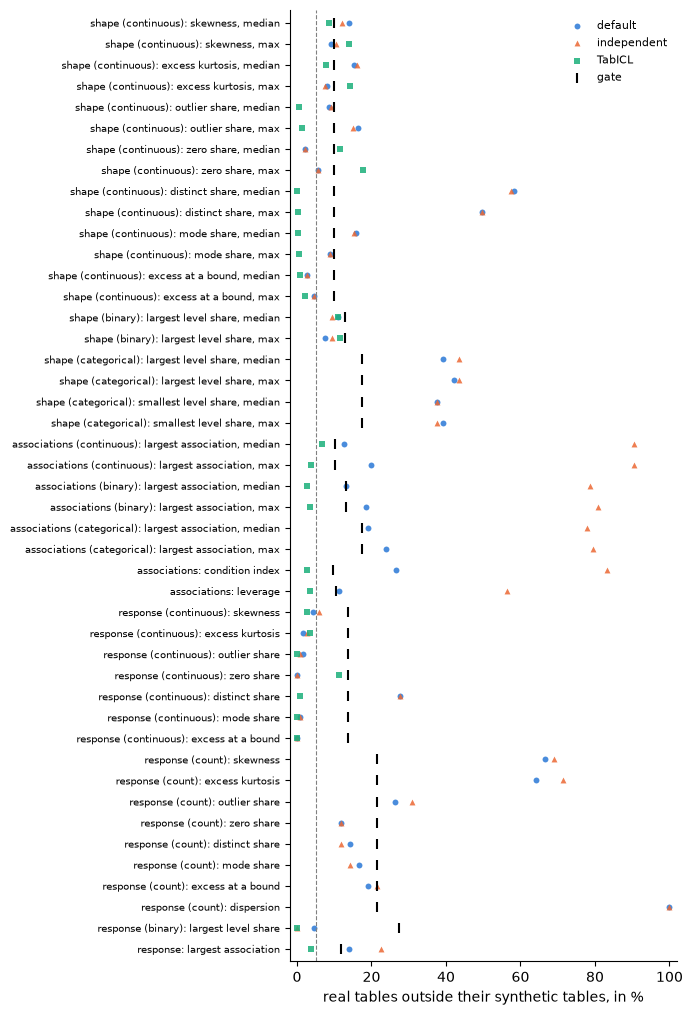

In [3]:
coverage = tabulateCoverage(PART, STRATUM)
plotCoverage(coverage)

Under the default simulator, 23 of the 45 statistics fail.<br>
On the associations between covariates, the independent simulator leaves 56% to 90% of the real tables outside, against 11% to 27% under the default, so the comparison detects the missing dependence.<br>
The excess at a bound passes for every column type and for the response.<br>
TabICL draws no categorical columns and no count responses, so it is ranked on 31 statistics.<br>
It fails on 4 of them, the largest skewness and excess kurtosis among a table's continuous columns and their zero share, and on no association.

### Table
Each row is a statistic that fails under the default simulator: the real tables ranked on it, the shares below and above all of their synthetic tables in %, and the mean rank.

In [4]:
failing = coverage[(coverage['arm'] == 'default') & coverage['fails']]
failing = failing.set_index(failing['axis'].map(labelStatistic))
failing = failing[['tables', 'below_share', 'above_share', 'mean_rank']]
failing = failing.rename(
    columns={'below_share': 'below in %', 'above_share': 'above in %', 'mean_rank': 'mean rank'}
)
failing = failing.astype({'tables': int}).round({'below in %': 1, 'above in %': 1, 'mean rank': 2})
showTable('Statistics that fail under the default simulator', failing.astype(str))
passing = coverage[(coverage['arm'] == 'default') & ~coverage['fails']]
print(f'{len(failing)} statistics fail and {len(passing)} pass.')

,tables,below in %,above in %,mean rank
"shape (continuous): skewness, median",324,6.2,7.7,0.57
"shape (continuous): excess kurtosis, median",324,7.4,8.0,0.49
"shape (continuous): outlier share, max",324,0.9,15.4,0.53
"shape (continuous): distinct share, median",324,58.3,0.0,0.1
"shape (continuous): distinct share, max",324,49.7,0.0,0.2
"shape (continuous): mode share, median",324,0.0,15.7,0.85
"shape (categorical): largest level share, median",69,39.1,0.0,0.33
"shape (categorical): largest level share, max",69,40.6,1.4,0.33
"shape (categorical): smallest level share, median",69,0.0,37.7,0.7
"shape (categorical): smallest level share, max",69,0.0,39.1,0.71


23 statistics fail and 22 pass.


The failures under the default simulator have these causes:
- **Discrete numbers:** real tables store rounded values, codes and years as numbers, so the median continuous column of the median real table takes a distinct value in 59% of its rows, while the default simulator draws nearly every value distinct. Tied values also give the rows lighter joint tails, so 8% of the real tables lie below all of their synthetic tables on the leverage.
- **Over-dispersed counts:** the variance of a real count response is 7 times its mean at the median, and the default simulator draws a Poisson count, whose ratio is 1.
- **Balanced levels:** the largest level of a real categorical column holds 33% of the rows at the median, against 44% of a drawn one.
- **Exact associations:** in 13% of the real tables one continuous column is a monotone function of another, and 9% have a rank-deficient design matrix, against 0.1% of the drawn tables.
- **Weaker associations of coded columns:** real binary and categorical columns are less associated with other columns than drawn ones (mean rank 0.35 to 0.38).
- **Stronger association of the response:** a real response is more associated with its closest covariate than a drawn one (mean rank 0.64).

On the skewness, excess kurtosis and outlier share of continuous columns, the real tables fall outside on both sides, for which we have no single cause.

## 4. Results: Realism

Coverage does not show whether a simulator also draws tables that no real table resembles.<br>
We therefore ask how close the synthetic tables lie to real tables, over all statistics at once.

### Table
Each row is a measure on one half of the real tables, and each column a simulator.<br>
On the certifying half, the precision is also given for 3 and for 10 neighbors.<br>
The last column compares the two halves of the real tables with each other, as a reference for the two-sample test.<br>
The best simulator per row is italicized.

In [5]:
scalars = report[report['axis'].isna() & (report['stratum'] == STRATUM)]
realism = scalars.pivot_table(index=['statistic', 'part'], columns='arm', values='value')
between = realism.loc[('c2st', 'fitting vs certifying'), 'real']
MEASURES = {
    f'precision, {PART} half': ('precision', PART),
    f'precision at 3 neighbors, {PART} half': ('precision_3', PART),
    f'precision at 10 neighbors, {PART} half': ('precision_10', PART),
    f'accuracy, {PART} half': ('c2st', PART),
    'precision, fitting half': ('precision', 'fitting'),
    'accuracy, fitting half': ('c2st', 'fitting'),
}
rows = {}
for label, (statistic, part) in MEASURES.items():
    values = realism.loc[(statistic, part), list(SIMULATORS)]
    # the accuracy nearest to chance, the precision nearest to a calibrated simulator's 0.5
    if statistic == 'c2st':
        best = values.idxmin()
    else:
        best = (values - 0.5).abs().idxmin()
    cells = {}
    for arm, simulator in SIMULATORS.items():
        cell = f'{values[arm]:.2f}'
        cells[simulator] = f'<i>{cell}</i>' if arm == best else cell
    if statistic == 'c2st':
        cells['real tables, one half vs the other'] = f'{between:.2f}'
    rows[label] = cells
showTable('Precision and two-sample test', pd.DataFrame(rows).T.fillna(''))

,default,independent,TabICL,"real tables, one half vs the other"
"precision, certifying half",0.42,0.31,0.46,
"precision at 3 neighbors, certifying half",0.43,0.33,0.46,
"precision at 10 neighbors, certifying half",0.41,0.28,0.47,
"accuracy, certifying half",0.92,0.95,0.90,0.60
"precision, fitting half",0.40,0.28,0.46,
"accuracy, fitting half",0.94,0.96,0.90,0.60


The precision of the default simulator is 0.42 on the certifying half and 0.40 on the fitting half, above the required 0.25.<br>
With 3 or 10 neighbors it is 0.43 and 0.41.<br>
TabICL scores 0.46, close to the 0.5 of a calibrated simulator.<br>
The independent simulator scores 0.31 and 0.28, so the precision does not reject it, and its missing dependence shows in the coverage.<br>
A random forest tells the tables of every simulator from the real ones, with an accuracy of 0.90 to 0.96.<br>
It tells the two halves of the real tables apart with an accuracy of 0.60.

## 5. Results: Sizes and column types

A synthetic table above takes its sizes and column types from its real table.<br>
Here we compare the real tables' sizes and type mix with what the default simulator draws on its own.

### Tables
The first table gives the share of real tables in % that lie outside each size limit of the defaults.<br>
The second compares the mean type mix of the real tables with that of 1,000 tables drawn from the defaults, with the Wasserstein-1 (W1) distance on their pooled ranks.

In [6]:
LIMITS = {
    'rows < 20': 'fewer than 20 rows',
    'rows > 15000': 'more than 15,000 rows',
    'design_columns > 19': 'more than 19 design columns',
    'design_columns > rows / 2': 'fewer than two rows per design column',
}
outside = report[report['statistic'] == 'outside_share']
outside = outside.pivot_table(index='axis', columns='part', values='value')
outside = (100 * outside.loc[list(LIMITS), ['fitting', 'certifying']]).round(1)
showTable('Real tables outside the default sizes, in %', outside.rename(index=LIMITS).astype(str))

MIX = {f'{type}_share': f'share of {type} columns' for type in TYPES}
MIX |= {'levels_median': 'levels of a column, median', 'levels_max': 'levels of a column, maximum'}
schema = report[report['statistic'].str.startswith('schema') & report['part'].isin([PART, 'every'])]
schema = schema.pivot_table(index='axis', columns=['statistic', 'arm'], values='value')
mix = pd.DataFrame(
    {
        'real tables': schema[('schema_mean', 'real')].round(2),
        'default': schema[('schema_mean', 'default')].round(2),
        'shown by real tables in %': (100 * schema[('schema_shown', 'real')]).round(0),
        'shown by default in %': (100 * schema[('schema_shown', 'default')]).round(0),
        'W1 distance': schema[('schema_distance', 'real')].round(2),
    }
)
showTable(
    'Type mix and levels, mean over the tables that show them',
    mix.loc[list(MIX)].rename(index=MIX).astype(str),
)

,fitting,certifying
fewer than 20 rows,14.8,17.1
"more than 15,000 rows",4.9,2.0
more than 19 design columns,10.9,12.9
fewer than two rows per design column,8.3,8.3


,real tables,default,shown by real tables in %,shown by default in %,W1 distance
share of continuous columns,0.75,0.39,100.0,100.0,0.28
share of count columns,0.0,0.0,100.0,100.0,0.0
share of binary columns,0.17,0.36,100.0,100.0,0.18
share of categorical columns,0.09,0.19,100.0,100.0,0.14
share of ordered columns,0.0,0.05,100.0,100.0,0.07
"levels of a column, median",4.51,4.49,21.0,58.0,0.56
"levels of a column, maximum",5.06,5.19,21.0,58.0,0.56


About one real table in six has fewer than 20 rows, and about one in eight has more than 19 design columns.<br>
Real tables hold more continuous columns than the default simulator draws (75% against 39% of a table's columns), and fewer binary and categorical ones.<br>
Only 21% of the real tables have a categorical or ordered column, against 58% of the drawn ones, which accounts for most of the distance on the levels.<br>
Where a table has such columns, their number of levels agrees.

### Table
Each row is a simulator on the real tables of other sizes, for which it is given the real table's sizes: the statistics that fail among those it is ranked on, the precision and the accuracy of the two-sample test.

In [7]:
other = tabulateCoverage(PART, 'outside')
scalars = report[
    report['axis'].isna() & (report['stratum'] == 'outside') & (report['part'] == PART)
]
scalars = scalars.pivot_table(index='arm', columns='statistic', values='value')
rows = {}
for arm, simulator in SIMULATORS.items():
    ranked = other[other['arm'] == arm]
    rows[simulator] = {
        'statistics that fail': f'{ranked["fails"].sum()} of {len(ranked)}',
        'precision': f'{scalars.loc[arm, "precision"]:.2f}',
        'accuracy': f'{scalars.loc[arm, "c2st"]:.2f}',
    }
showTable('Real tables of other sizes', pd.DataFrame(rows).T)

,statistics that fail,precision,accuracy
default,25 of 44,0.45,0.83
independent,24 of 44,0.35,0.87
TabICL,1 of 30,0.59,0.89


On the real tables of other sizes, the default simulator fails on 25 of 44 statistics, at a precision of 0.45.<br>
TabICL fails on 1 of 30 statistics and reaches a precision of 0.59.<br>
These tables lie outside the sizes that the default simulator draws on its own, so they do not enter the conclusion.

## 6. Conclusion

| goal | default simulator |
|---|---|
| real tables are covered on every statistic | false: 23 of 45 statistics fail |
| the comparison detects independent covariates | true |
| a precision of at least 0.25 | true: 0.42 |
| the default sizes hold the real tables | false: 17% of the real tables have fewer than 20 rows, 13% more than 19 design columns |
| the default type mix matches the real tables | false: real tables hold about twice the share of continuous columns |

The default simulator does not yet draw tables like the real ones: it lacks discrete numbers, over-dispersed counts and exact associations, and its levels are less balanced.

## References

Lopez-Paz, D., & Oquab, M. (2017). Revisiting classifier two-sample tests. *International Conference on Learning Representations*. https://arxiv.org/abs/1610.06545

Mardia, K. V. (1970). Measures of multivariate skewness and kurtosis with applications. *Biometrika*, 57(3), 519-530. https://doi.org/10.1093/biomet/57.3.519

Naeem, M. F., Oh, S. J., Uh, Y., Choi, Y., & Yoo, J. (2020). Reliable fidelity and diversity metrics for generative models. *Proceedings of the 37th International Conference on Machine Learning*, 7176-7185. https://arxiv.org/abs/2002.09797

Qu, J., Holzmüller, D., Varoquaux, G., & Le Morvan, M. (2026). TabICLv2: A better, faster, scalable, and open tabular foundation model. *International Conference on Machine Learning*. https://arxiv.org/abs/2602.11139

Talts, S., Betancourt, M., Simpson, D., Vehtari, A., & Gelman, A. (2020). Validating Bayesian inference algorithms with simulation-based calibration. *arXiv preprint*. https://arxiv.org/abs/1804.06788